### [GALT] Vežba 3: Raspodela zvezda u Galaksiji

### <font color='yellow'> Ideja vežbe: Određivanje Galaktičkog potencijala i rotacione krive iz sintetičke populacije zvezda. </font>

#### <font color='red'>Na kraju svakog koraka, kada odradite ono što je bilo pitanje potrebno je iskomentarisati rešenje!</font>

#### Uvod

U prošloj vežbi, generisali smo sintetičku populaciju zvezda koja prati Salpeterov zakon:
$$\frac{dN}{dM} \propto M^{-\alpha}, \quad \alpha \approx 2.35.$$
U nastavku smo pretpostavili da su zvezde ravnomerno raspoređene u sferi, da bismo analizirali Malmkvisnovu neobjektivnost. Međutim, mi znamo da raspodela zvezda (i generalno materije) u Galaksiji nije uniformna.

Pretpostavimo da je prostorna gustina zvezda opisana eksponencijalnim diskom:

$$
\rho(R,z)=\rho_0\exp(-R/R_d)\exp(-|z|/z_d),
$$

gde su R i z cilindrične koordinate, $R_d$ i $z_d$ skala diska i visinska skala. Ugao $\varphi$ je uniforman na $(0,2\pi)$.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve

##### <font color="green">1. Semplovati 100 000 zvezda koje prate Salpeterovu IMF. Uzeti da je minimalna masa zvezde 0.08MSun, a maksimalna npr. 200MSun. (Ovo je iz prethodne vežbe.)</font>

In [3]:
# Инверзно узорковање маса звијезда према Салпетеровој функцији
Ммин = 0.08
Ммакс = 200.0
α = 2.35
rng = np.random.default_rng(42)
# Салпетерова функција масе звијезда
def салпетер(м):
    return м**(-α)
# Узорковање маса звијезда по Салпетеровој функцији
def узорковање_звјезданих_маса(n_узорака):
    # Прављење узорака из равномјерне расподјеле
    u = rng.random(n_узорака)
    # Инверзна кумулативна функција за Салпетерову расподјелу
    m_узорака = (Ммин**(1-α) + u*(Ммакс**(1-α)-Ммин**(1-α)))**(1/(1-α))
    return m_узорака
# Генерисање 100000 звијезда
масе = узорковање_звјезданих_маса(100000)
масе

array([0.24067841, 0.12273466, 0.34066809, ..., 0.14695742, 0.08802142,
       0.57842712], shape=(100000,))

##### <font color="green">2. Semplovati cilindrične koordinate za svaku zvezdu. (Uzeti, npr. $R_d$ = 3kpc i $z_d$ = 0.2kpc.) Objasniti kako se semplovanje vrši. </font>

In [4]:
# Узорковање цилиндричних координата за звијезде у галаксији по већ узоркованим масама
Р_д = 3.0  # kpc, полупречник диска
З_д = 0.2  # kpc, висина диска
def узорковање_координата(масе):
    n_звјезда = len(масе)
    # Узорковање радијалне координате Р по гама расподјели
    Р = rng.gamma(shape=2.0, scale=Р_д, size=n_звјезда)
    # Узорковање азимуталне координате φ равномјерно између 0 и 2π
    φ = rng.uniform(0, 2*np.pi, n_звјезда)
    # Узорковање вертикалне координате Z по Лапласовој расподјели
    Z = rng.laplace(loc=0.0, scale=З_д, size=n_звјезда)
    return Р, φ, Z
координате = узорковање_координата(масе)
координате

(array([10.36032129,  7.48656658, 20.92536276, ...,  9.49739133,
         7.40675685,  8.21504116], shape=(100000,)),
 array([4.32011709, 5.59624034, 3.23843477, ..., 3.75876807, 4.41813947,
        4.59921678], shape=(100000,)),
 array([ 0.18718518, -0.43140351,  0.58886724, ..., -0.00617046,
         0.12109779, -0.20942375], shape=(100000,)))

Врши се на сличан начин као узорковање маса, само прилагођеним расподјелама за одговарајуће величине. Као што се види, редом: гама, истородна и Лапласова расподјела. На крају се само позове та функција да изврши конкретно узорковање.

##### <font color="green">3. Prikazati raspodelu zvezda u 3D, kao i (R, z) i (x, y) ravni.</font>

In [5]:
import ipywidgets as widgets
from IPython.display import display, clear_output
# Издвајање цилиндричних координата
Р, φ, Z = координате
# Прелазак у Декартове координате
x = Р * np.cos(φ)
y = Р * np.sin(φ)
# Падајући мени за избор приказа
избор_графика = widgets.Dropdown(
    options=[("3D расподјела звијезда", "3D"), ("Расподјела у (R, z) равни", "RZ"),
        ("Расподјела у (x, y) равни", "XY")], description="Приказ:",
    style={"description_width": "initial"})
излаз = widgets.Output()
def приказ_расподјеле(промјена):
    with излаз:
        clear_output(wait=True)
        фигура = plt.figure(figsize=(8, 6))
        if избор_графика.value == "3D":
            оса = фигура.add_subplot(111, projection="3d")
            оса.scatter(x, y, Z, s=0.3, alpha=0.3)
            оса.set_xlabel("x [kpc]")
            оса.set_ylabel("y [kpc]")
            оса.set_zlabel("z [kpc]")
            оса.set_title("3D расподјела звијезда у Галаксији")
        elif избор_графика.value == "RZ":
            оса = фигура.add_subplot(111)
            оса.scatter(Р, Z, s=0.3, alpha=0.3)
            оса.set_xlabel("R [kpc]")
            оса.set_ylabel("z [kpc]")
            оса.set_title("Расподјела звијезда у (R, z) равни")
        elif избор_графика.value == "XY":
            оса = фигура.add_subplot(111)
            оса.scatter(x, y, s=0.3, alpha=0.3)
            оса.set_xlabel("x [kpc]")
            оса.set_ylabel("y [kpc]")
            оса.set_title("Расподјела звијезда у (x, y) равни")
            оса.set_aspect("equal")
        plt.tight_layout()
        plt.show()
        plt.close(фигура)
избор_графика.observe(приказ_расподјеле, names="value")
display(избор_графика, излаз)
приказ_расподјеле(None)

Dropdown(description='Приказ:', options=(('3D расподјела звијезда', '3D'), ('Расподјела у (R, z) равни', 'RZ')…

Output()

Potrebno je odraditi normalizaciju, tako da celi disk ima masu $M_{disk}$. Uzeti, npr. $M_{disk}=5\cdot 10^{10}M_\odot$. Dakle, ako integralimo prethodno zadatku gustinu po zapremini, možemo da odredimo vrednost $\rho_0$. 

##### <font color="green">4. Izračunati $\rho_0$.</font>

In [8]:
Мдиск = 5e10  # Маса диска у масама Сунца
ρ0 = Мдиск / (4 * np.pi * Р_д**2 * З_д)  # Средишња густина диска
print(f"Средишња густина диска: {ρ0:.3e} M_☉/kpc^3")

Средишња густина диска: 2.210e+09 M_☉/kpc^3


Dalje, koristeći Poasonovu jednačinu: 

$$\nabla^2 \Phi = 4\pi G\rho$$

možemo da odredimo Galaktički potencijal koji odgovara zadatoj raspodeli gustine.

Poasonova jednačina u cilindričnim koordinatama:

$$ \frac{1}{R}\frac{\partial}{\partial R}
\left(R\frac{\partial\Phi}{\partial R}\right)
+\frac{\partial^2\Phi}{\partial z^2}
=4\pi G\rho(R,z).
$$

Koristiti metodu konačnih razlika na dvodimenzionalnoj mreži $(R,z)$, za oblast $0\leq R\leq30\mathrm{kpc}$ i $-10\leq z\leq10\mathrm{kpc}$.

Primeniti sledeće granične uslove:

Na spoljnim granicama oblasti pretpostaviti da se potencijal približava potencijalu tačkaste mase ukupne mase diska:

$$
\Phi(R,z)=-\frac{GM}{\sqrt{R^2+z^2}}.
$$

Na osi simetrije (R=0) primeniti uslov:

$$
\left.\frac{\partial\Phi}{\partial R}\right|_{R=0}=0.
$$

U nastavku je napisana funkcija solve_poisson koja numerički rešava ovaj problem.

In [11]:
def solve_poisson(rho, R, z, M, G):
    # broj tačaka numeričke mreže u R i z pravcu
    NR = len(R)
    NZ = len(z)
    # korak
    dR = R[1] - R[0]
    dz = z[1] - z[0]
    # na spoljnim granicama unapred zadajemo potencijal, pa ne moramo da ga racunamo kao nepoznatu
    nR = NR - 1
    nZ = NZ - 2
    # ukupan broj tačaka u kojima računamo vrednosti potencijala
    N = nR * nZ
    # 2D mrežu (i,j) preslikavamo u 1D indeks k, jer sistem rešavamo u obliku matrice A i vektora b
    def idx(i, j):
        return i * nZ + (j - 1)
    # formiramo praznu matricu A
    # koristimo lil_matrix jer je većina elemenata matrice nula
    A = lil_matrix((N, N))
    # desna strana Poasonove jednacine: 4*pi*G*rho
    b = (4 * np.pi * G * rho[:nR, 1:-1]).ravel().copy()
    # kreiramo 2D mrežu koordinata
    RR, ZZ = np.meshgrid(R, z, indexing="ij")
    # na spoljnim granicama oblasti potencijal aproksimiramo potencijalom tačkaste mase ukupne mase M
    # kao što piše iznad u graničnim uslovima, imamo ovo +1e-30 da ne bi došlo do deljenja sa 0 
    phi_boundary = -G * M / np.sqrt(RR**2 + ZZ**2 + 1e-30)
    # prolazimo kroz sve tačke u kojima je potencijal nepoznat
    for i in range(nR):
        for j in range(1, NZ - 1):
            # 1D indeks trenutne tačke
            k = idx(i, j)
            # -----------------------------------------
            # DRUGI IZVOD PO Z
            # -----------------------------------------
            # Drugi izvod po z aproksimiramo metodom konacnih razlika:
            #
            # d^2Phi/dz^2 ~
            # (Phi[i,j+1] - 2*Phi[i,j] + Phi[i,j-1]) / dz^2
            A[k, k] += -2 / dz**2
            # dodajemo doprinose susednih tačaka u z pravcu
            for jj in (j - 1, j + 1):
                if 1 <= jj <= NZ - 2:
                    # ako je susedna tačka unutar oblasti
                    # nepoznatih vrednosti, dodajemo je u matricu A
                    A[k, idx(i, jj)] += 1 / dz**2
                else:
                    # ako je susedna tačka na granici oblasti, njen potencijal je vec poznat
                    b[k] -= phi_boundary[i, jj] / dz**2
            # -----------------------------------------
            # RADIJALNI DEO POASONOVE JEDNACINE
            # -----------------------------------------
            if i == 0:
                # Na osi R = 0 izraz 1/R nije definisan.
                # Zbog osne simetrije važi dPhi/dR = 0 na R = 0.
                # Koristimo posebnu aproksimaciju radijalnog operatora
                # na samoj osi.
                A[k, k] += -4 / dR**2
                A[k, idx(1, j)] += 4 / dR**2
            else:
                # Za R > 0 koristimo aproksimaciju konačnih razlika
                Ri = R[i]
                # koeficijenti uz potencijal u susednim radijalnim tackama R[i+1] i R[i-1].
                cp = 1 / dR**2 + 1 / (2 * Ri * dR)
                cm = 1 / dR**2 - 1 / (2 * Ri * dR)
                #koeficijent uz potencijal u trenutnoj tački
                A[k, k] += -2 / dR**2
                # doprinos unutršnje susedne tacke R[i-1]
                A[k, idx(i - 1, j)] += cm
                # doprinos susedne tacke R[i+1]
                if i + 1 < nR:
                    #ako je tačka unutar oblasti nepoznatih vrednosti, njen doprinos dodajemo u matricu A
                    A[k, idx(i + 1, j)] += cp
                else:
                    #  ako je susedna tačka na granici oblasti, njen potencijal je vec poznat
                    b[k] -= cp * phi_boundary[i + 1, j]
    # -----------------------------------------
    # REŠAVANJE SISTEMA LINEARNIH JEDNAČINA
    # -----------------------------------------
    # Nakon diskretizacije Poasonove jednačine dobijamo sistem:
    #
    # A * Phi = b
    #
    # Funkcija spsolve numerički rešava ovaj sistem.
    # Rezultat je vektor vrednosti potencijala.
    #
    # zatim ga vraćamo u oblik 2D mreže (nR, nZ).
    phi_inner = spsolve(A.tocsr(), b).reshape(nR, nZ)
    # -----------------------------------------
    # REKONSTRUKCIJA MATRICE POTENCIJALA
    # -----------------------------------------
    # kreiramo matricu u kojoj ce biti sačuvane vrednosti potencijala u svim tačkama prvobitne mreže
    Phi = np.empty((NR, NZ))
    # na spoljašnjim granicama imamo unapred zadate vrednosti potencijala
    Phi[-1, :] = phi_boundary[-1, :]
    Phi[:, 0] = phi_boundary[:, 0]
    Phi[:, -1] = phi_boundary[:, -1]
    # unutrašnje vrednosti popunjavamo numeričkim rešenjem
    Phi[:nR, 1:-1] = phi_inner
    # funkcija vraća matricu gravitacionog potencijala Phi(R,z)
    return Phi

Pogledati kako funkcija radi i ne koristiti ju kao black-box. 

##### <font color="green">5. Pozivajući solve_possion funkciju, rešiti Poasonovu jednačinu i prikazati 2D mapu potencijala.</font>

Полаза од Њутнове гравитационе константе у SI систему:
$G_{\mathrm{SI}}=6.67430\times10^{-11}\ \mathrm{m^3\,kg^{-1}\,s^{-2}}.$

За прелазак на астрономске јединице је:
$$1\,M_\odot=1.98847\times10^{30}\ \mathrm{kg},$$

$$1\,\mathrm{kpc}=3.08568\times10^{19}\ \mathrm{m},
\qquad 1\,\mathrm{km}=10^3\ \mathrm{m}.$$
Зато:
$$G = 6.67430\times10^{-11} \cdot \frac{1.98847\times10^{30}} {3.08568\times10^{19}\cdot(10^3)^2}.$$
Одатле:
$$\boxed{G=4.30091\times10^{-6} \ \mathrm{kpc\,M_\odot^{-1}(km/s)^2}}$$

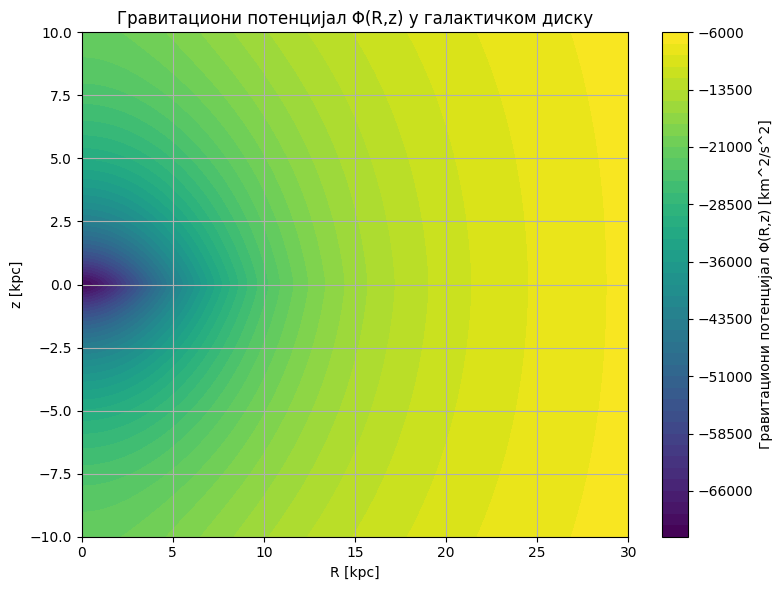

In [23]:
# Дефинисање дводимензионалне мреже (R, z)
Р_мрежа = np.linspace(0, 30, 241)
З_мрежа = np.linspace(-10, 10, 161)
РР, ЗЗ = np.meshgrid(Р_мрежа, З_мрежа, indexing="ij")
# Израчунавање густине на свакој тачки мреже
ρ = ρ0 * np.exp(-РР / Р_д) * np.exp(-np.abs(ЗЗ) / З_д)
G = 4.30091e-6 # Гравитациона константа у kpc M_sun^-1 (km/s)^2
Φ = solve_poisson(ρ, Р_мрежа, З_мрежа, Мдиск, G) # Решавање Поасонове једначине
plt.figure(figsize=(8, 6))
plt.contourf(Р_мрежа, З_мрежа, Φ.T, levels=50, cmap="viridis")
plt.colorbar(label="Гравитациони потенцијал Φ(R,z) [km^2/s^2]")
plt.xlabel("R [kpc]")
plt.ylabel("z [kpc]")
plt.title("Гравитациони потенцијал Φ(R,z) у галактичком диску")
plt.grid()
plt.tight_layout()
plt.show()

Ako znamo potencijal, brzinu rotacije možemo odrediti koristeći izraz:
$$ \frac{v_c^2}{R} = \frac{\delta\Phi}{\delta R} $$

##### <font color="green">6. Koristeći prethodni izraz, prikazati rotacionu krivu. </font>

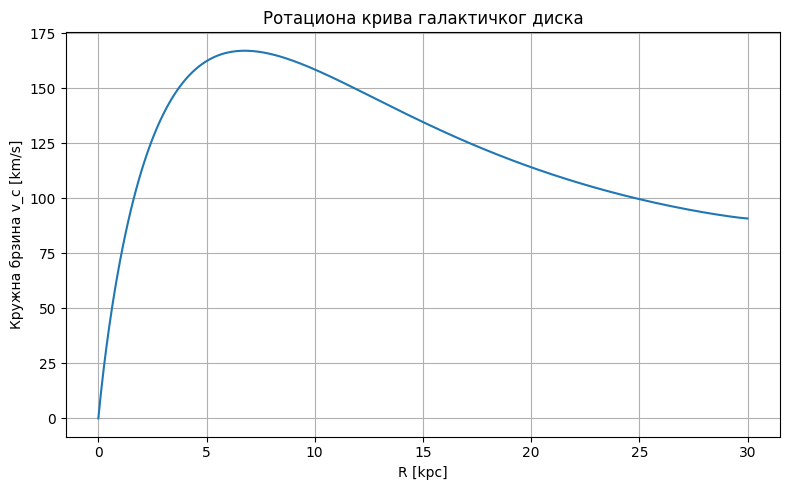

In [ ]:
# Издвајање потенцијала у галактичкој равни z = 0
i_z0 = np.argmin(np.abs(З_мрежа))
Φ_раван = Φ[:, i_z0]
dΦ_dR = np.gradient(Φ_раван, Р_мрежа, edge_order=2) # Радијалан извод потенцијала
v_c = np.sqrt(Р_мрежа * dΦ_dR) # Кружна брзина
# Приказ ротационе криве
plt.figure(figsize=(8, 5))
plt.plot(Р_мрежа, v_c)
plt.xlabel("R [kpc]")
plt.ylabel("Кружна брзина v_c [km/s]")
plt.title("Ротациона крива галактичког диска")
plt.grid()
plt.tight_layout()
plt.show()

##### <font color="green">7. Odrediti brzinu Sunca iz ove rotacione krive i uporediti sa prihvaćenom vrijednošću. </font> 

In [27]:
v_сунце = np.interp(8.0, Р_мрежа, v_c)  # Кружна брзина у положају Сунца (R = 8 kpc)
print(f"Кружна брзина у положају Сунца (R = 8 kpc): {v_сунце:.2f} km/s")
print(f"Прихваћена вриједност кружне брзине у положају Сунца је око 220-230 km/s, што није у складу са астрономским посматрањима.")

Кружна брзина у положају Сунца (R = 8 kpc): 165.50 km/s
Прихваћена вриједност кружне брзине у положају Сунца је око 220-230 km/s, што није у складу са астрономским посматрањима.


Ова брзина је добијена интерполацијом из двије тачке најближе тачки која би одговарала Сунцу. Овај поједностављен модел гравитациони узима само масу диска у обзир, а историјски је познато да је оваква разлика теорије и посматрања дала мотивацију за теорију о тамној материји.

##### <font color="green">8. Kako se menja rotaciona kriva ako je ukupna masa diska dva puta veća, z nepromenjene vrednosti $R_d$ i $z_d$. </font> 

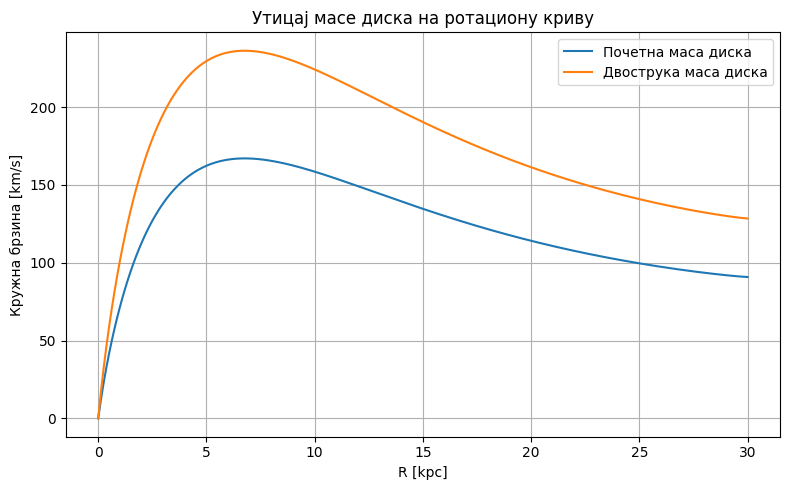

In [28]:
# Удвостручавање масе диска
ρ_2 = 2 * ρ
Φ_2 = solve_poisson(ρ_2, Р_мрежа, З_мрежа, 2 * Мдиск, G)

# Издвајање потенцијала у галактичкој равни
Φ_2_раван = Φ_2[:, i_z0]

# Нумерички извод и нова ротациона крива
dΦ_2_dR = np.gradient(Φ_2_раван, Р_мрежа, edge_order=2)
v_c_2 = np.sqrt(Р_мрежа * dΦ_2_dR)

# Поређење ротационих кривих
plt.figure(figsize=(8, 5))
plt.plot(Р_мрежа, v_c, label="Почетна маса диска")
plt.plot(Р_мрежа, v_c_2, label="Двострука маса диска")
plt.xlabel("R [kpc]")
plt.ylabel("Кружна брзина [km/s]")
plt.title("Утицај масе диска на ротациону криву")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

Прво, густина се мијења - удвостручена маса значи удвостручену густину по класичном обрасцу који је већ коришћен изнад $ρ = M / (4πzr^2)$. Ова информације се може даље убацити у главни образац за ротациону криву: $ \frac{v_c^2}{R} = \frac{\delta\Phi}{\delta R} $.

Извод је линеаран оператор и утиче само на координату. Како је кружна брзина квадрирана, то ће рећи да је кружна брзина једнака коријену $R\frac{\delta\Phi}{\delta R}$. Фактор природно искаче из $ρ_0$ као два, али је под коријеном у самом изразу, што значи да са удвострученом масом се ротациона крива (тј. кружна брзина) увећа коријен из два пута.